# Análisis paso a paso: MercadoLibre — Libros de terror

Notebook para reutiliza en el Quiz 2, usando el dataset de `dataset_mercadolibre-scraper-espanol-castellano_2026-08-18_13-29-04-255.csv` (scraping de publicaciones de "libros de terror" en MercadoLibre).

**Antes de empezar:** subí el archivo `dataset_mercadolibre-scraper-espanol-castellano_2026-08-18_13-29-04-255.csv` a la sesión de Colab (icono de carpeta a la
izquierda → *Subir a almacenamiento de la sesión*) o montá tu Google Drive.

## Estructura
- **Parte A — ETL**: extracción, diagnóstico, limpieza y transformación del dataset crudo
- **Parte B — Ejercicios**: 5 secciones que reciclan los ejercicios del quiz original sobre el
  dataset ya limpio


---
# Parte A — ETL (Extract, Transform, Load)

Antes de analizar el Dataset, siempre conviene pasar por un proceso de ETL:
extraerlo, entender su calidad, quedarnos solo con lo relevante, limpiarlo y transformarlo a un
formato consistente. Esto evita errores silenciosos más adelante (por ejemplo, calcular un promedio
sobre una columna con texto en vez de números).

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

df_raw = pd.read_csv('/content/dataset_mercadolibre-scraper-espanol-castellano_2026-08-18_13-29-04-255 - dataset_mercadolibre-scraper-espanol-castellano_2026-08-18_13-29-04-255.csv', header='infer')
print(df_raw.shape)
df_raw.head(5)


(478, 40)


,Envio,Moneda,SKU,Tiempo,Vendedor,articuloTitulo,cantidadVendida,disponibleEn,enStock,envioDesde,...,produtoReviews,promociones,resultadosTotales,sellerID,tipoRegistro,tipoResultado,ubicacion,vertical,verticalID,zProductoLink
0,Llega gratis hoy,ARS,MLA22203654,2026-08-18T13:26:29.695Z,Zivals Tienda oficial,Libro Fuego Y Sangre (canción De Hielo Y Fuego...,1000.0,NaN,True,NaN,...,4.9,NaN,+9.999 resultados,NaN,busqueda,ORGANIC,NaN,CORE,CORE,https://www.mercadolibre.com.ar/libro-fuego-y-...
1,Llega gratis mañana,ARS,MLA19864989,2026-08-18T13:26:29.695Z,NaN,Mariana Enriquez Los peligros de fumar en la c...,5000.0,NaN,True,NaN,...,4.8,NaN,+9.999 resultados,NaN,busqueda,ORGANIC,NaN,CORE,CORE,https://www.mercadolibre.com.ar/mariana-enriqu...
2,Llega gratis hoy,ARS,MLA20913273,2026-08-18T13:26:29.695Z,Deser Libros Tienda oficial,It Stephen King Español Debolsillo,1000.0,NaN,True,NaN,...,4.9,NaN,+9.999 resultados,NaN,busqueda,ORGANIC,NaN,CORE,CORE,https://www.mercadolibre.com.ar/it-stephen-kin...
3,Llega gratis hoy,ARS,MLA22090889,2026-08-18T13:26:29.695Z,NaN,Socorro 12 Cuentos Para Caerse De Miedo: 12 cu...,1000.0,NaN,True,NaN,...,4.9,NaN,+9.999 resultados,NaN,busqueda,ORGANIC,NaN,CORE,CORE,https://www.mercadolibre.com.ar/socorro-12-cue...
4,Llega gratis hoy Enviado por FULL,ARS,MLA26050668,2026-08-18T13:26:29.695Z,MASLIBROS Tienda oficial,"El Exorcista, De Blatty, William Peter. Editor...",100.0,NaN,True,NaN,...,4.9,NaN,+9.999 resultados,NaN,busqueda,ORGANIC,NaN,CORE,CORE,https://www.mercadolibre.com.ar/el-exorcista-d...


## A.1 — Extracción y diagnóstico inicial

Revisamos tipos de datos, cantidad de nulos por columna y si hay filas duplicadas. Esto nos dice
qué columnas están realmente utilizables y cuáles no aportan información.

In [65]:
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 40 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Envio                  445 non-null    object 
 1   Moneda                 478 non-null    object 
 2   SKU                    478 non-null    object 
 3   Tiempo                 478 non-null    object 
 4   Vendedor               300 non-null    object 
 5   articuloTitulo         478 non-null    object 
 6   cantidadVendida        276 non-null    float64
 7   disponibleEn           0 non-null      float64
 8   enStock                412 non-null    object 
 9   envioDesde             1 non-null      object 
 10  envioGratis            478 non-null    bool   
 11  esCompraInternacional  478 non-null    bool   
 12  esPrecioPorCantidad    478 non-null    bool   
 13  esTiendaOficial        478 non-null    bool   
 14  highlight              144 non-null    object 
 15  idProd

In [66]:
df_raw.describe()

,cantidadVendida,disponibleEn,itemPosition,nuevoPrecio,numeroEvaluaciones,productoMarca,produtoReviews,sellerID,ubicacion
count,276.000000,0.0,478.000000,478.000000,204.000000,0.0,272.000000,0.0,0.0
mean,155.978261,NaN,24.719665,33809.451883,47.186275,NaN,4.868382,NaN,NaN
std,457.548352,NaN,13.889685,22995.924897,116.193972,NaN,0.134303,NaN,NaN
min,25.000000,NaN,1.000000,4130.000000,1.000000,NaN,4.300000,NaN,NaN
25%,50.000000,NaN,13.000000,19365.000000,3.000000,NaN,4.800000,NaN,NaN
50%,50.000000,NaN,25.000000,28395.500000,11.500000,NaN,4.900000,NaN,NaN
75%,100.000000,NaN,37.000000,42210.750000,43.000000,NaN,5.000000,NaN,NaN
max,5000.000000,NaN,49.000000,187803.000000,1071.000000,NaN,5.000000,NaN,NaN


In [67]:
df_raw.isna().sum().sort_values(ascending=False).head(15)


,0
disponibleEn,478
productoMarca,478
ubicacion,478
sellerID,478
envioDesde,477
promociones,452
precioDiscount,357
precioAnterior,357
highlight,334
installments,332


In [68]:
df_raw.duplicated().sum()


np.int64(0)

**Diagnóstico:** hay columnas 100% nulas (`disponibleEn`, `productoMarca`, `ubicacion`,
`sellerID`), columnas constantes que no aportan variabilidad (`palabraClave`, `vertical`, `Moneda`,
`tipoRegistro`, etc.) y columnas técnicas de scraping (`imgDireccion`, `zProductoLink`,
`idProductoUsuario`, `idVariacion`) que no son relevantes para el análisis. No hay filas duplicadas.

## A.2 — Selección de columnas relevantes

Nos quedamos solo con las columnas que van a usarse en el análisis: identificación de la
publicación, precio, vendedor, indicadores de tienda oficial y envío, métricas de venta y
evaluaciones, y datos de cuotas.

In [69]:
columnas_relevantes = [
    'idPublicacion', 'articuloTitulo', 'Vendedor', 'esTiendaOficial',
    'nuevoPrecio', 'precioAnterior', 'precioDiscount', 'envioGratis',
    'enStock', 'cantidadVendida', 'numeroEvaluaciones', 'produtoReviews',
    'installments', 'highlight', 'itemPosition', 'Tiempo'
]
df = df_raw[columnas_relevantes].copy()
df.shape


(478, 16)

In [70]:
df

,idPublicacion,articuloTitulo,Vendedor,esTiendaOficial,nuevoPrecio,precioAnterior,precioDiscount,envioGratis,enStock,cantidadVendida,numeroEvaluaciones,produtoReviews,installments,highlight,itemPosition,Tiempo
0,MLA1438985527,Libro Fuego Y Sangre (canción De Hielo Y Fuego...,Zivals Tienda oficial,True,49500,NaN,NaN,True,True,1000.0,636.0,4.9,6 cuotas de 11136,NaN,1,2026-08-18T13:26:29.695Z
1,MLA1664274515,Mariana Enriquez Los peligros de fumar en la c...,NaN,False,17500,NaN,NaN,True,True,5000.0,558.0,4.8,Mismo precio 6 cuotas de 2916,NaN,2,2026-08-18T13:26:29.695Z
2,MLA2907767984,It Stephen King Español Debolsillo,Deser Libros Tienda oficial,True,32900,NaN,NaN,True,True,1000.0,685.0,4.9,Mismo precio 3 cuotas de 10966,NaN,3,2026-08-18T13:26:29.695Z
3,MLA2202982806,Socorro 12 Cuentos Para Caerse De Miedo: 12 cu...,NaN,False,23900,NaN,NaN,True,True,1000.0,215.0,4.9,NaN,ÚLTIMAS 2 | ÚLTIMAS UNIDADES,4,2026-08-18T13:26:29.695Z
4,MLA2610718784,"El Exorcista, De Blatty, William Peter. Editor...",MASLIBROS Tienda oficial,True,31257,NaN,NaN,True,True,100.0,63.0,4.9,NaN,ÚLTIMAS 4 | ÚLTIMAS UNIDADES,5,2026-08-18T13:26:29.695Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
473,MLA1960823347,Terror In Venice - Paul Rosner,MASLIBROS Tienda oficial,True,28171,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,44,2026-08-18T13:29:04.114Z
474,MLA1960839695,The Terror Scrolls - Ferdinand J Delery,MASLIBROS Tienda oficial,True,25090,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,45,2026-08-18T13:29:04.114Z
475,MLA1960848151,Buried Deep Inside : A Novel Of Cyber-terror -...,MASLIBROS Tienda oficial,True,24641,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,46,2026-08-18T13:29:04.114Z
476,MLA1948288777,El Exorcista - William Peter Blatty,NaN,False,55611,NaN,NaN,True,True,NaN,NaN,NaN,6 cuotas de 12511,NaN,47,2026-08-18T13:29:04.114Z


## A.3 — Renombrado de columnas

Renombramos a nombres en español, cortos y consistentes (`snake_case`). Esto hace que el código de
los ejercicios sea más legible.

In [71]:
df = df.rename(columns={
    'idPublicacion': 'id_publicacion',
    'articuloTitulo': 'titulo',
    'Vendedor': 'vendedor',
    'esTiendaOficial': 'tienda_oficial',
    'nuevoPrecio': 'precio',
    'precioAnterior': 'precio_anterior',
    'precioDiscount': 'descuento_pct',
    'envioGratis': 'envio_gratis',
    'enStock': 'en_stock',
    'cantidadVendida': 'vendidos',
    'numeroEvaluaciones': 'evaluaciones',
    'produtoReviews': 'reviews',
    'installments': 'cuotas_texto',
    'highlight': 'destacado',
    'itemPosition': 'posicion',
    'Tiempo': 'fecha_scrapeo',
})
df.columns.tolist()


['id_publicacion',
 'titulo',
 'vendedor',
 'tienda_oficial',
 'precio',
 'precio_anterior',
 'descuento_pct',
 'envio_gratis',
 'en_stock',
 'vendidos',
 'evaluaciones',
 'reviews',
 'cuotas_texto',
 'destacado',
 'posicion',
 'fecha_scrapeo']

## A.4 — Tratamiento de nulos

Cada columna con nulos se trata según su significado real:
- `vendidos` y `evaluaciones` en NaN significan que la publicación **no tiene ventas o evaluaciones
  registradas** → se completan con 0.
- `vendedor` en NaN significa que MercadoLibre no expuso el nombre del vendedor → se completa con
  `'No especificado'`.
- `en_stock` en NaN se interpreta como que el dato no fue informado → se completa con `False` por
  seguridad.
- `destacado` en NaN significa que la publicación no tiene ningún cartel destacado → se completa con
  `'Sin destacado'`.
- `precio_anterior` en NaN significa que el producto no tuvo descuento previo → se completa con el
  mismo `precio` actual.
- `descuento_pct` en NaN sigue la misma lógica → se completa con `'0% OFF'`.
- `reviews` (puntaje de 1 a 5) se deja en NaN cuando no hay evaluaciones: no tiene sentido
  inventarle una nota a un producto sin reviews.

In [72]:
df['vendidos'] = df['vendidos'].fillna(0)
df['evaluaciones'] = df['evaluaciones'].fillna(0)
df['vendedor'] = df['vendedor'].fillna('No especificado')
df['en_stock'] = df['en_stock'].fillna(False)
df['destacado'] = df['destacado'].fillna('Sin destacado')

/tmp/ipykernel_451/2466897010.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['en_stock'] = df['en_stock'].fillna(False)


In [74]:
df.precio.describe()

,precio
count,478.000000
mean,33809.451883
std,22995.924897
min,4130.000000
25%,19365.000000
50%,28395.500000
75%,42210.750000
max,187803.000000


In [78]:
df.precio

,precio
0,49500
1,17500
2,32900
3,23900
4,31257
...,...
473,28171
474,25090
475,24641
476,55611


In [73]:
df.precio_anterior.describe()

,precio_anterior
count,121
unique,97
top,12000
freq,4


In [75]:
df['precio_anterior'] = df['precio_anterior'].fillna(df['precio'])

In [77]:
df.precio_anterior

,precio_anterior
0,49500
1,17500
2,32900
3,23900
4,31257
...,...
473,28171
474,25090
475,24641
476,55611


In [76]:
df.precio_anterior.describe()

,precio_anterior
count,478
unique,385
top,20000
freq,6


In [79]:

df['descuento_pct'] = df['descuento_pct'].fillna('0% OFF')

df.isna().sum()


,0
id_publicacion,0
titulo,0
vendedor,0
tienda_oficial,0
precio,0
precio_anterior,0
descuento_pct,0
envio_gratis,0
en_stock,0
vendidos,0


## A.5 — Conversión de tipos

`fecha_scrapeo` llega como texto y la convertimos a `datetime`. `vendidos` y `evaluaciones` deben
ser enteros (no tiene sentido "vender 5.0 unidades"). `precio_anterior` llega como texto con comas
de miles en algunos casos, así que lo limpiamos y convertimos a entero.

In [15]:
df['fecha_scrapeo'] = pd.to_datetime(df['fecha_scrapeo'])
df['vendidos'] = df['vendidos'].astype(int)
df['evaluaciones'] = df['evaluaciones'].astype(int)
df['precio_anterior'] = df['precio_anterior'].astype(str).str.replace(',', '').astype(float).astype(int)

df.dtypes


,0
id_publicacion,object
titulo,object
vendedor,object
tienda_oficial,bool
precio,int64
precio_anterior,int64
descuento_pct,object
envio_gratis,bool
en_stock,bool
vendidos,int64


## A.6 — Transformación / Feature engineering

Creamos columnas nuevas más útiles para el análisis:
- `descuento_pct_num`: el porcentaje de descuento como número, extraído del texto `'10% OFF'`.
- `cantidad_cuotas`: la cantidad de cuotas, extraída del texto `'6 cuotas de 11136'`.
- `tiene_descuento`: booleano que indica si la publicación tiene descuento.
- `ingreso_estimado`: `precio × vendidos`, una estimación de cuánto generó cada publicación.

In [16]:
df['descuento_pct_num'] = df['descuento_pct'].str.extract(r'(\d+)').astype(int).fillna(0)
df['cantidad_cuotas'] = df['cuotas_texto'].str.extract(r'(\d+)\s*cuotas').astype(float).fillna(0)
df['tiene_descuento'] = df['descuento_pct_num'] > 0
df['ingreso_estimado'] = df['precio'] * df['vendidos']

df[['descuento_pct', 'descuento_pct_num', 'cuotas_texto', 'cantidad_cuotas', 'tiene_descuento', 'ingreso_estimado']].head(8)


,descuento_pct,descuento_pct_num,cuotas_texto,cantidad_cuotas,tiene_descuento,ingreso_estimado
0,0% OFF,0,6 cuotas de 11136,6.0,False,49500000
1,0% OFF,0,Mismo precio 6 cuotas de 2916,6.0,False,87500000
2,0% OFF,0,Mismo precio 3 cuotas de 10966,3.0,False,32900000
3,0% OFF,0,NaN,0.0,False,23900000
4,0% OFF,0,NaN,0.0,False,3125700
5,0% OFF,0,NaN,0.0,False,2929500
6,0% OFF,0,NaN,0.0,False,219500000
7,10% OFF,10,NaN,0.0,True,3033000


## A.7 — Validación final del dataset limpio

Revisamos que el dataset quedó consistente: mismas 478 filas que al inicio (no perdimos datos),
tipos correctos y sin nulos en las columnas clave que vamos a usar en los ejercicios.

In [17]:
print(df.shape)
df.info()


(478, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   id_publicacion     478 non-null    object             
 1   titulo             478 non-null    object             
 2   vendedor           478 non-null    object             
 3   tienda_oficial     478 non-null    bool               
 4   precio             478 non-null    int64              
 5   precio_anterior    478 non-null    int64              
 6   descuento_pct      478 non-null    object             
 7   envio_gratis       478 non-null    bool               
 8   en_stock           478 non-null    bool               
 9   vendidos           478 non-null    int64              
 10  evaluaciones       478 non-null    int64              
 11  reviews            272 non-null    float64            
 12  cuotas_texto       146 non-null    objec

In [18]:
df.head(5)


,id_publicacion,titulo,vendedor,tienda_oficial,precio,precio_anterior,descuento_pct,envio_gratis,en_stock,vendidos,evaluaciones,reviews,cuotas_texto,destacado,posicion,fecha_scrapeo,descuento_pct_num,cantidad_cuotas,tiene_descuento,ingreso_estimado
0,MLA1438985527,Libro Fuego Y Sangre (canción De Hielo Y Fuego...,Zivals Tienda oficial,True,49500,49500,0% OFF,True,True,1000,636,4.9,6 cuotas de 11136,Sin destacado,1,2026-08-18 13:26:29.695000+00:00,0,6.0,False,49500000
1,MLA1664274515,Mariana Enriquez Los peligros de fumar en la c...,No especificado,False,17500,17500,0% OFF,True,True,5000,558,4.8,Mismo precio 6 cuotas de 2916,Sin destacado,2,2026-08-18 13:26:29.695000+00:00,0,6.0,False,87500000
2,MLA2907767984,It Stephen King Español Debolsillo,Deser Libros Tienda oficial,True,32900,32900,0% OFF,True,True,1000,685,4.9,Mismo precio 3 cuotas de 10966,Sin destacado,3,2026-08-18 13:26:29.695000+00:00,0,3.0,False,32900000
3,MLA2202982806,Socorro 12 Cuentos Para Caerse De Miedo: 12 cu...,No especificado,False,23900,23900,0% OFF,True,True,1000,215,4.9,NaN,ÚLTIMAS 2 | ÚLTIMAS UNIDADES,4,2026-08-18 13:26:29.695000+00:00,0,0.0,False,23900000
4,MLA2610718784,"El Exorcista, De Blatty, William Peter. Editor...",MASLIBROS Tienda oficial,True,31257,31257,0% OFF,True,True,100,63,4.9,NaN,ÚLTIMAS 4 | ÚLTIMAS UNIDADES,5,2026-08-18 13:26:29.695000+00:00,0,0.0,False,3125700


El DataFrame `df` (ya limpio) es el que se usa en **todos** los ejercicios de la Parte B.

---
# Parte B — Ejercicios

Cada sección repasa funciones importantes de Numpy y Pandas`df`.

## Sección 1 — Promedios, máximos y mínimos por grupo


**Paso 1.** Para responder "precio promedio de Tienda Oficial", primero filtramos las filas donde
`tienda_oficial == True`, y sobre ese subconjunto aplicamos `.precio.mean()`.

In [19]:
# 1. Precio promedio de publicaciones de Tienda Oficial
df[df.tienda_oficial == True].precio.mean()


np.float64(36461.63333333333)

In [20]:
df[df.tienda_oficial == True].precio

,precio
0,49500
2,32900
4,31257
5,29295
7,30330
...,...
471,38596
472,30527
473,28171
474,25090


**Paso 2.** Repetimos la misma lógica pero filtrando lo opuesto (`== False`).

In [21]:
# 2. Precio promedio de publicaciones que NO son de Tienda Oficial
df[df.tienda_oficial == False].precio.mean()


np.float64(29339.483146067414)

**Paso 3 y 4.** Ahora cambiamos la condición de filtro: en vez de `tienda_oficial`, usamos
`envio_gratis`.

In [22]:
# 3. Precio promedio de publicaciones con envío gratis
df[df.envio_gratis == True].precio.mean()


np.float64(34416.332584269665)

In [23]:
# 4. Precio promedio de publicaciones sin envío gratis
df[df.envio_gratis == False].precio.mean()


np.float64(25625.757575757576)

**Paso 5 y 6.** Para el precio más alto/bajo dentro de un grupo, usamos `.max()` / `.min()` en
vez de `.mean()`, manteniendo la misma lógica de filtrado.

In [24]:
# 5. Precio más alto entre las publicaciones de Tienda Oficial
df[df.tienda_oficial == True].precio.max()


187803

In [25]:
# 6. Precio más bajo entre las publicaciones que NO son de Tienda Oficial
df[df.tienda_oficial == False].precio.min()


4390

**Paso 7 y 8.** Podemos combinar dos condiciones con el operador `&` (y lógico). Cada condición
va entre paréntesis.

In [26]:
# 7. Precio más bajo entre publicaciones de Tienda Oficial con reviews > 4.8
df[(df.tienda_oficial == True) & (df.reviews > 4.8)].precio.min()


4130

In [27]:
# 8. Precio más alto entre publicaciones NO oficiales con reviews < 4.8
df[(df.tienda_oficial == False) & (df.reviews < 4.8)].precio.max()


31999

**Paso 9.** Por último, aplicamos la misma lógica de filtrado pero calculando el promedio sobre
otra columna numérica (`evaluaciones`) en vez de `precio`.

In [28]:
# 9. Promedio de evaluaciones en publicaciones con envío gratis
df[df.envio_gratis == True].evaluaciones.mean()


np.float64(21.024719101123594)

---
## Sección 2 — Filtros condicionales y ordenamiento


**Paso 1.** Filtramos las publicaciones con `vendidos >= 1000` y sumamos su precio con `.sum()`.

In [81]:
df[df.vendidos > 1000]

,id_publicacion,titulo,vendedor,tienda_oficial,precio,precio_anterior,descuento_pct,envio_gratis,en_stock,vendidos,evaluaciones,reviews,cuotas_texto,destacado,posicion,fecha_scrapeo
1,MLA1664274515,Mariana Enriquez Los peligros de fumar en la c...,No especificado,False,17500,17500,0% OFF,True,True,5000.0,558.0,4.8,Mismo precio 6 cuotas de 2916,Sin destacado,2,2026-08-18T13:26:29.695Z
6,MLA2264564004,Nuestra Parte De Noche: Premio Herralde De Novela,No especificado,False,43900,43900,0% OFF,True,True,5000.0,1071.0,4.9,NaN,ÚLTIMAS 4 | ÚLTIMAS UNIDADES,7,2026-08-18T13:26:29.695Z


In [80]:
df[df.vendidos >= 1000]

,id_publicacion,titulo,vendedor,tienda_oficial,precio,precio_anterior,descuento_pct,envio_gratis,en_stock,vendidos,evaluaciones,reviews,cuotas_texto,destacado,posicion,fecha_scrapeo
0,MLA1438985527,Libro Fuego Y Sangre (canción De Hielo Y Fuego...,Zivals Tienda oficial,True,49500,49500,0% OFF,True,True,1000.0,636.0,4.9,6 cuotas de 11136,Sin destacado,1,2026-08-18T13:26:29.695Z
1,MLA1664274515,Mariana Enriquez Los peligros de fumar en la c...,No especificado,False,17500,17500,0% OFF,True,True,5000.0,558.0,4.8,Mismo precio 6 cuotas de 2916,Sin destacado,2,2026-08-18T13:26:29.695Z
2,MLA2907767984,It Stephen King Español Debolsillo,Deser Libros Tienda oficial,True,32900,32900,0% OFF,True,True,1000.0,685.0,4.9,Mismo precio 3 cuotas de 10966,Sin destacado,3,2026-08-18T13:26:29.695Z
3,MLA2202982806,Socorro 12 Cuentos Para Caerse De Miedo: 12 cu...,No especificado,False,23900,23900,0% OFF,True,True,1000.0,215.0,4.9,NaN,ÚLTIMAS 2 | ÚLTIMAS UNIDADES,4,2026-08-18T13:26:29.695Z
6,MLA2264564004,Nuestra Parte De Noche: Premio Herralde De Novela,No especificado,False,43900,43900,0% OFF,True,True,5000.0,1071.0,4.9,NaN,ÚLTIMAS 4 | ÚLTIMAS UNIDADES,7,2026-08-18T13:26:29.695Z
10,MLA2400041226,"Un Lugar Soleado Para Gente Sombria, Enriquez,...",No especificado,False,15200,15200,0% OFF,True,True,1000.0,395.0,4.9,NaN,Sin destacado,11,2026-08-18T13:26:29.695Z
19,MLA1432748622,Las Cronicas De Dune - Frank Herbert - Debolsi...,TIENDALAVOZ Tienda oficial,True,75999,75999,0% OFF,True,True,1000.0,301.0,4.9,6 cuotas de 17098,Sin destacado,20,2026-08-18T13:26:29.695Z
22,MLA1398670395,It (eso) - Stephen King (Ed debolsillo),No especificado,False,63848,67209,5% OFF,True,True,1000.0,0.0,4.9,Mismo precio 3 cuotas de 21282,OFERTA IMPERDIBLE,23,2026-08-18T13:26:29.695Z
24,MLA3664788262,Chainsaw Man 08 Ivrea Manga,No especificado,False,10999,10999,0% OFF,True,True,1000.0,0.0,5.0,NaN,Sin destacado,25,2026-08-18T13:26:29.695Z
70,MLA1262050328,Masacre En El Comedor - Reato - Sudamericana -...,LIBRENTA Tienda oficial,True,42686,47499,10% OFF,True,True,1000.0,154.0,4.8,NaN,ÚLTIMAS 2 | ÚLTIMAS UNIDADES,23,2026-08-18T13:26:48.487Z


In [29]:
# 1. Suma de precios de publicaciones con vendidos >= 1000
df[df.vendidos >= 1000].precio.sum()


np.int64(404422)

**Paso 2.** Para comparar contra "el promedio general", primero calculamos ese promedio
(`df.evaluaciones.mean()`) y lo usamos como condición de filtro.

In [30]:
# 2. Precio promedio de publicaciones con más evaluaciones que el promedio general
df[df.evaluaciones > df.evaluaciones.mean()].precio.mean()


np.float64(36425.84210526316)

**Paso 3.** Guardamos el resultado del filtro combinado en una variable (`condicion`) y
consultamos `.shape[0]` para saber cuántas filas cumplen ambas condiciones.

In [31]:
# 3. Publicaciones con reviews > 4.5 y menos evaluaciones que el promedio
condicion = df[(df.reviews > 4.5) & (df.evaluaciones < df.evaluaciones.mean())]
condicion.shape[0]


185

In [83]:
df[(df.evaluaciones < df.evaluaciones.mean())]

,id_publicacion,titulo,vendedor,tienda_oficial,precio,precio_anterior,descuento_pct,envio_gratis,en_stock,vendidos,evaluaciones,reviews,cuotas_texto,destacado,posicion,fecha_scrapeo
8,MLA1972578797,Pack 2 Libros Clasicos Terror - Dracula Y Fran...,EDICIONES CONTINENTE Tienda oficial,True,23238,23238,0% OFF,True,False,0.0,0.0,NaN,Mismo precio 3 cuotas de 7746,Sin destacado,9,2026-08-18T13:26:29.695Z
9,MLA3643218910,Juego Y Aprendo Terror Barco De Papel +8 Años ...,No especificado,False,15820,15820,0% OFF,True,False,0.0,0.0,NaN,NaN,Sin destacado,10,2026-08-18T13:26:29.695Z
13,MLA3678582070,X3 Terror Y Misterio Dumas Oliphant Gogol Suda...,No especificado,False,33000,33000,0% OFF,True,False,0.0,0.0,NaN,NaN,Sin destacado,14,2026-08-18T13:26:29.695Z
14,MLA3277236288,"It (eso). Tú También Flotarás, De Stephen King...",No especificado,False,63890,63890,0% OFF,True,True,100.0,0.0,4.8,6 cuotas de 14374,Sin destacado,15,2026-08-18T13:26:29.695Z
15,MLA2848855454,"La Milla Verde, De King, Stephen. Editorial De...",No especificado,False,31521,33995,7% OFF,True,True,100.0,0.0,4.8,NaN,ÚLTIMAS 4 | ÚLTIMAS UNIDADES,16,2026-08-18T13:26:29.695Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
473,MLA1960823347,Terror In Venice - Paul Rosner,MASLIBROS Tienda oficial,True,28171,28171,0% OFF,False,False,0.0,0.0,NaN,NaN,Sin destacado,44,2026-08-18T13:29:04.114Z
474,MLA1960839695,The Terror Scrolls - Ferdinand J Delery,MASLIBROS Tienda oficial,True,25090,25090,0% OFF,False,False,0.0,0.0,NaN,NaN,Sin destacado,45,2026-08-18T13:29:04.114Z
475,MLA1960848151,Buried Deep Inside : A Novel Of Cyber-terror -...,MASLIBROS Tienda oficial,True,24641,24641,0% OFF,False,False,0.0,0.0,NaN,NaN,Sin destacado,46,2026-08-18T13:29:04.114Z
476,MLA1948288777,El Exorcista - William Peter Blatty,No especificado,False,55611,55611,0% OFF,True,True,0.0,0.0,NaN,6 cuotas de 12511,Sin destacado,47,2026-08-18T13:29:04.114Z


In [82]:
df[(df.reviews > 4.5)]

,id_publicacion,titulo,vendedor,tienda_oficial,precio,precio_anterior,descuento_pct,envio_gratis,en_stock,vendidos,evaluaciones,reviews,cuotas_texto,destacado,posicion,fecha_scrapeo
0,MLA1438985527,Libro Fuego Y Sangre (canción De Hielo Y Fuego...,Zivals Tienda oficial,True,49500,49500,0% OFF,True,True,1000.0,636.0,4.9,6 cuotas de 11136,Sin destacado,1,2026-08-18T13:26:29.695Z
1,MLA1664274515,Mariana Enriquez Los peligros de fumar en la c...,No especificado,False,17500,17500,0% OFF,True,True,5000.0,558.0,4.8,Mismo precio 6 cuotas de 2916,Sin destacado,2,2026-08-18T13:26:29.695Z
2,MLA2907767984,It Stephen King Español Debolsillo,Deser Libros Tienda oficial,True,32900,32900,0% OFF,True,True,1000.0,685.0,4.9,Mismo precio 3 cuotas de 10966,Sin destacado,3,2026-08-18T13:26:29.695Z
3,MLA2202982806,Socorro 12 Cuentos Para Caerse De Miedo: 12 cu...,No especificado,False,23900,23900,0% OFF,True,True,1000.0,215.0,4.9,NaN,ÚLTIMAS 2 | ÚLTIMAS UNIDADES,4,2026-08-18T13:26:29.695Z
4,MLA2610718784,"El Exorcista, De Blatty, William Peter. Editor...",MASLIBROS Tienda oficial,True,31257,31257,0% OFF,True,True,100.0,63.0,4.9,NaN,ÚLTIMAS 4 | ÚLTIMAS UNIDADES,5,2026-08-18T13:26:29.695Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
439,MLA1514458935,"Guy de Maupassant Cuentos completos de terror,...",LIBRENTA Tienda oficial,True,81917,81917,0% OFF,True,True,25.0,0.0,4.8,6 cuotas de 18429,Sin destacado,10,2026-08-18T13:29:04.113Z
444,MLA1388526839,"En Las Montañas De La Locura Vol 1, De H.p. Lo...",LIBERATE Tienda oficial,True,48537,48537,0% OFF,True,True,25.0,8.0,4.8,6 cuotas de 10920,Sin destacado,15,2026-08-18T13:29:04.113Z
445,MLA1540983132,Joyland - Stephen King - Editorial Debolsillo,LIBERATE Tienda oficial,True,25726,25726,0% OFF,False,True,100.0,26.0,4.7,NaN,Sin destacado,16,2026-08-18T13:29:04.113Z
450,MLA2616715952,"Libro: Carcoma. Martinez, Layla. Amor De Madre...",LIBRENTA Tienda oficial,True,43000,43000,0% OFF,True,True,25.0,3.0,5.0,NaN,Sin destacado,21,2026-08-18T13:29:04.113Z


In [32]:
condicion

,id_publicacion,titulo,vendedor,tienda_oficial,precio,precio_anterior,descuento_pct,envio_gratis,en_stock,vendidos,evaluaciones,reviews,cuotas_texto,destacado,posicion,fecha_scrapeo,descuento_pct_num,cantidad_cuotas,tiene_descuento,ingreso_estimado
14,MLA3277236288,"It (eso). Tú También Flotarás, De Stephen King...",No especificado,False,63890,63890,0% OFF,True,True,100,0,4.8,6 cuotas de 14374,Sin destacado,15,2026-08-18 13:26:29.695000+00:00,0,6.0,False,6389000
15,MLA2848855454,"La Milla Verde, De King, Stephen. Editorial De...",No especificado,False,31521,33995,7% OFF,True,True,100,0,4.8,NaN,ÚLTIMAS 4 | ÚLTIMAS UNIDADES,16,2026-08-18 13:26:29.695000+00:00,7,0.0,True,3152100
16,MLA2003317978,Coraline (En inglés),No especificado,False,22792,22792,0% OFF,True,True,100,18,4.7,NaN,ÚLTIMAS 3 | ÚLTIMAS UNIDADES,17,2026-08-18 13:26:29.695000+00:00,0,0.0,False,2279200
20,MLA1842129075,"El Rey De Amarillo Y Otros Relatos De Terror, ...",PYQ Tienda oficial,True,8500,8500,0% OFF,True,True,25,6,5.0,NaN,Sin destacado,21,2026-08-18 13:26:29.695000+00:00,0,0.0,False,212500
22,MLA1398670395,It (eso) - Stephen King (Ed debolsillo),No especificado,False,63848,67209,5% OFF,True,True,1000,0,4.9,Mismo precio 3 cuotas de 21282,OFERTA IMPERDIBLE,23,2026-08-18 13:26:29.695000+00:00,5,3.0,True,63848000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
436,MLA2243136240,"Viento Por La Cerradura, El",LIBRENTA Tienda oficial,True,27747,27747,0% OFF,False,True,100,18,4.9,NaN,Sin destacado,7,2026-08-18 13:29:04.112000+00:00,0,0.0,False,2774700
439,MLA1514458935,"Guy de Maupassant Cuentos completos de terror,...",LIBRENTA Tienda oficial,True,81917,81917,0% OFF,True,True,25,0,4.8,6 cuotas de 18429,Sin destacado,10,2026-08-18 13:29:04.113000+00:00,0,6.0,False,2047925
444,MLA1388526839,"En Las Montañas De La Locura Vol 1, De H.p. Lo...",LIBERATE Tienda oficial,True,48537,48537,0% OFF,True,True,25,8,4.8,6 cuotas de 10920,Sin destacado,15,2026-08-18 13:29:04.113000+00:00,0,6.0,False,1213425
450,MLA2616715952,"Libro: Carcoma. Martinez, Layla. Amor De Madre...",LIBRENTA Tienda oficial,True,43000,43000,0% OFF,True,True,25,3,5.0,NaN,Sin destacado,21,2026-08-18 13:29:04.113000+00:00,0,0.0,False,1075000


**Paso 4.** `sort_values('columna', ascending=False)` ordena el DataFrame de mayor a menor
según esa columna. Con `[['titulo', 'precio']]` nos quedamos solo con las columnas que nos
interesan mostrar, y `.head(3)` muestra las primeras 3 filas.

In [33]:
# 4. Top 3 publicaciones más caras
df_ordenado = df.sort_values('precio', ascending=False)
df_ordenado[['titulo', 'precio']].head(3)


,titulo,precio
456,Libro Aliens Omnibus La Etapa Original 3 - Gen...,187803
301,"Moonshine Integral, De Azzarello, Brian; Risso...",150000
90,"Las mil y una noches, de Anónimo. Editorial De...",130500


---
## Sección 3 — Nueva variable, `groupby()` y `pivot_table()`


**Paso 1.** La columna `ingreso_estimado = precio × vendidos` ya se creó en el paso A.6 del ETL —
por eso el ETL previo hace que este ejercicio sea directo.

In [34]:
# 1. Recordamos la columna creada en el ETL
df[['titulo', 'precio', 'vendidos', 'ingreso_estimado']].head(5)


,titulo,precio,vendidos,ingreso_estimado
0,Libro Fuego Y Sangre (canción De Hielo Y Fuego...,49500,1000,49500000
1,Mariana Enriquez Los peligros de fumar en la c...,17500,5000,87500000
2,It Stephen King Español Debolsillo,32900,1000,32900000
3,Socorro 12 Cuentos Para Caerse De Miedo: 12 cu...,23900,1000,23900000
4,"El Exorcista, De Blatty, William Peter. Editor...",31257,100,3125700


**Paso 2.** `groupby('columna')['otra_columna'].mean()` agrupa las filas según los valores de
`columna` y calcula el promedio de `otra_columna` dentro de cada grupo.

In [35]:
df.groupby('tienda_oficial')['precio']

In [36]:
# 2. Precio promedio por tipo de vendedor, usando groupby()
df.groupby('tienda_oficial')['precio'].mean()


,precio
tienda_oficial,
False,29339.483146
True,36461.633333


**Paso 3.** `pivot_table()` hace lo mismo que `groupby()` pero permite cruzar **dos**
variables categóricas a la vez: una en `index` (filas) y otra en `columns` (columnas).

In [37]:
# 3. Precio promedio cruzando Tienda Oficial (filas) y envío gratis (columnas), usando pivot_table()
df.pivot_table(values='precio', index='tienda_oficial', columns='envio_gratis', aggfunc='mean')


envio_gratis,False,True
tienda_oficial,,
False,22083.000000,29771.416667
True,27166.086957,37233.465704


---
## Sección 4 — Tabla de frecuencia y visualización comparada


**Paso 1.** `value_counts()` cuenta cuántas veces aparece cada valor de una columna — es la "tabla
de frecuencia". `.head(10)` nos quedamos con los 10 más frecuentes y `.sort_values()` los ordena de
mayor a menor antes de graficar.

In [84]:
df['vendedor'].value_counts()

,count
vendedor,
No especificado,178
MASLIBROS Tienda oficial,34
LIBRENTA Tienda oficial,34
SBS Librerias Tienda oficial,33
NADIR LIBROS Tienda oficial,31
Zivals Tienda oficial,25
LIBERATE Tienda oficial,14
ENTELEQUIA Tienda oficial,11
La Revistería Comics Tienda oficial,11


In [87]:
# 1. Tabla de frecuencia: top 10 vendedores con más publicaciones (excluyendo "No especificado")
top_vendedores = df[df['vendedor'] != 'No especificado']['vendedor'].value_counts().head(10)
top_vendedores = top_vendedores.sort_values(ascending=False)
top_vendedores


,count
vendedor,
MASLIBROS Tienda oficial,34
LIBRENTA Tienda oficial,34
SBS Librerias Tienda oficial,33
NADIR LIBROS Tienda oficial,31
Zivals Tienda oficial,25
LIBERATE Tienda oficial,14
ENTELEQUIA Tienda oficial,11
La Revistería Comics Tienda oficial,11
Libreria Hernandez Tienda oficial,11


Con la tabla de frecuencia lista, la visualizamos como gráfico de barras con `plt.bar()`.

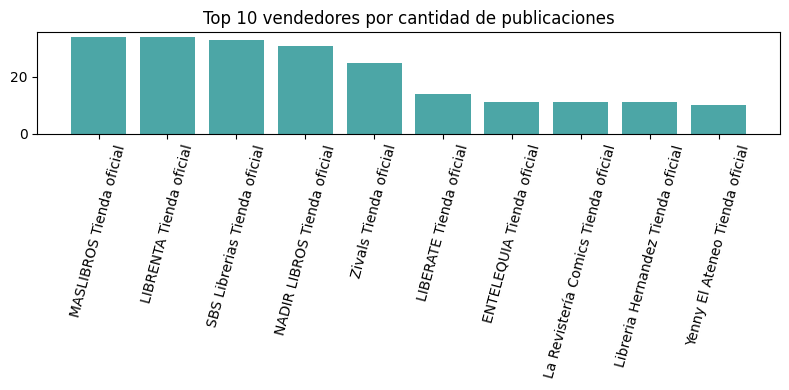

In [88]:
plt.figure(figsize=(8, 4))
plt.bar(top_vendedores.index.astype(str), top_vendedores.values, color='teal', alpha=0.7)
plt.xticks(rotation=75)
plt.title('Top 10 vendedores por cantidad de publicaciones')
plt.tight_layout()
plt.show()


**Paso 2.** Dividimos el DataFrame en dos subconjuntos con un filtro booleano (igual que en la
Sección 1), y superponemos dos histogramas en el mismo gráfico usando el objeto `figure` +
`add_axes`, tal como pedía el ejercicio original.

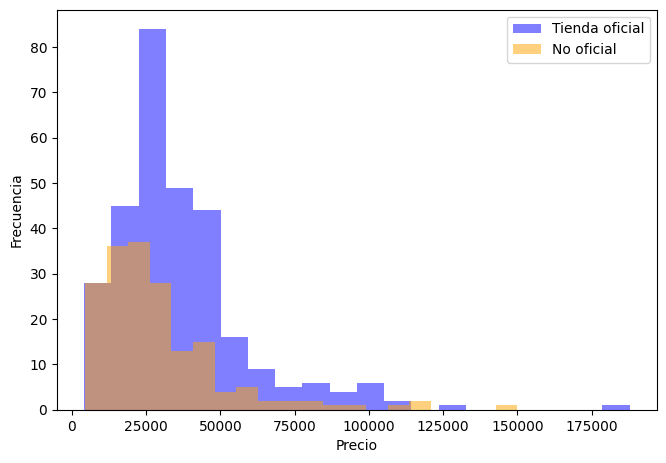

In [89]:
# 2. Dividimos el dataset por tipo de vendedor, ESTE TEMA QUEDA AFUERA
df_oficial = df[df['tienda_oficial'] == True]
df_no_oficial = df[df['tienda_oficial'] == False]

fig = plt.figure(figsize=[6, 4])
my_axes = fig.add_axes([0, 0, 1, 1])
my_axes.hist(df_oficial['precio'], bins=20, alpha=0.5, label='Tienda oficial', color='blue')
my_axes.hist(df_no_oficial['precio'], bins=20, alpha=0.5, label='No oficial', color='orange')
my_axes.set_xlabel('Precio')
my_axes.set_ylabel('Frecuencia')
my_axes.legend()
plt.show()


**Paso 3.** Con los resultados de los pasos 1 y 2, redactamos un breve análisis:

Las publicaciones de Tienda Oficial concentran la mayor cantidad de anuncios entre los vendedores
más frecuentes, y en promedio tienen precios más altos que las publicaciones que no son de tiendas
oficiales (visto en la Sección 1). La distribución de precios de ambos grupos está concentrada en
valores bajos-medios, pero las tiendas oficiales muestran más presencia en el rango de precios
altos, lo que es consistente con el precio promedio mayor calculado antes.

---
## Sección 5 — Fundamentos de NumPy aplicados al dataset

**Paso 1.** `.to_numpy()` convierte una columna de Pandas en un array de NumPy.

In [90]:
precios = df['precio'].to_numpy()
precios[:10]


array([49500, 17500, 32900, 23900, 31257, 29295, 43900, 30330, 23238,
       15820])

In [43]:
precios

array([ 49500,  17500,  32900,  23900,  31257,  29295,  43900,  30330,
        23238,  15820,  15200,  29159,  29270,  33000,  63890,  31521,
        22792,  29453,  60002,  75999,   8500,  32900,  63848,  21297,
        10999,  17820,  35000,  23200,  31018,  16100,  40800,  17100,
        32800,  33990,  23800,  34960,  16900,  89000,  58330,  31053,
        34600,  39651, 120700,  62670,  39522,  32900,  24900,  45000,
        11000,  32990,  62910,  40500,  13999,  78000,  10120,  24840,
        25555,  36005,  16900,  33028,  36612,  13050,  55385,  20425,
        25555,   8000,  16900,  19320,  35100,  22900,  42686,  28242,
        89388,  26000,  42499,  11292,  32300,  11000,  23849,   6000,
        26900,  27990,   9000,   8500,  42550,  43177,  29313, 113390,
        27260,  30500, 130500,  71100,  48900,  17100,  29193,  39900,
        54449,  23999,  20699,  30700,  27400,  31787,  35149,  30305,
        43900,  20938,  12990,  45380,   4130,  23670,  51200,  23000,
      

In [44]:
precios

array([ 49500,  17500,  32900,  23900,  31257,  29295,  43900,  30330,
        23238,  15820,  15200,  29159,  29270,  33000,  63890,  31521,
        22792,  29453,  60002,  75999,   8500,  32900,  63848,  21297,
        10999,  17820,  35000,  23200,  31018,  16100,  40800,  17100,
        32800,  33990,  23800,  34960,  16900,  89000,  58330,  31053,
        34600,  39651, 120700,  62670,  39522,  32900,  24900,  45000,
        11000,  32990,  62910,  40500,  13999,  78000,  10120,  24840,
        25555,  36005,  16900,  33028,  36612,  13050,  55385,  20425,
        25555,   8000,  16900,  19320,  35100,  22900,  42686,  28242,
        89388,  26000,  42499,  11292,  32300,  11000,  23849,   6000,
        26900,  27990,   9000,   8500,  42550,  43177,  29313, 113390,
        27260,  30500, 130500,  71100,  48900,  17100,  29193,  39900,
        54449,  23999,  20699,  30700,  27400,  31787,  35149,  30305,
        43900,  20938,  12990,  45380,   4130,  23670,  51200,  23000,
      

**Paso 2.** `.ndim` nos dice cuántas dimensiones tiene el array (1 = vector, 2 = matriz, etc.).

In [45]:
precios

array([ 49500,  17500,  32900,  23900,  31257,  29295,  43900,  30330,
        23238,  15820,  15200,  29159,  29270,  33000,  63890,  31521,
        22792,  29453,  60002,  75999,   8500,  32900,  63848,  21297,
        10999,  17820,  35000,  23200,  31018,  16100,  40800,  17100,
        32800,  33990,  23800,  34960,  16900,  89000,  58330,  31053,
        34600,  39651, 120700,  62670,  39522,  32900,  24900,  45000,
        11000,  32990,  62910,  40500,  13999,  78000,  10120,  24840,
        25555,  36005,  16900,  33028,  36612,  13050,  55385,  20425,
        25555,   8000,  16900,  19320,  35100,  22900,  42686,  28242,
        89388,  26000,  42499,  11292,  32300,  11000,  23849,   6000,
        26900,  27990,   9000,   8500,  42550,  43177,  29313, 113390,
        27260,  30500, 130500,  71100,  48900,  17100,  29193,  39900,
        54449,  23999,  20699,  30700,  27400,  31787,  35149,  30305,
        43900,  20938,  12990,  45380,   4130,  23670,  51200,  23000,
      

In [46]:
len(precios)

478

In [47]:
precios.ndim


1

**Paso 3 y 4.** El indexado (`arr[i]`) accede a un elemento puntual; el slicing (`arr[i:j]`)
devuelve un sub-array desde la posición `i` hasta `j-1`.

In [48]:
# Primer elemento
precios[0]


np.int64(49500)

In [49]:
# Slice: posiciones 2, 3 y 4
precios[2:5]


array([32900, 23900, 31257])

**Paso 5.** `np.concatenate()` une dos arrays en uno solo.

In [50]:
oficial_arr = df_oficial['precio'].to_numpy()

In [51]:
no_oficial_arr = df_no_oficial['precio'].to_numpy()

In [52]:
oficial_arr[:3]

array([49500, 32900, 31257])

In [53]:
no_oficial_arr[:3]

array([17500, 23900, 43900])

In [54]:
np.concatenate((oficial_arr[:3], no_oficial_arr[:3]))


array([49500, 32900, 31257, 17500, 23900, 43900])

In [55]:
np.concatenate((no_oficial_arr[:3], oficial_arr[:3]))


array([17500, 23900, 43900, 49500, 32900, 31257])

**Paso 6.** `np.where(condicion)` devuelve los índices donde se cumple la condición.

In [56]:
indices = np.where(precios > 100000)
len(indices[0])


12

In [93]:
precios[42]

np.int64(120700)

In [92]:
indices[0]

array([ 42,  87,  90, 142, 160, 301, 319, 328, 350, 425, 447, 456])

**Paso 7.** `np.random.randint(100)` devuelve un entero aleatorio entre 0 y 100.

In [57]:
np.random.randint(100)


17

**Paso 8.** `np.add()` y `np.subtract()` operan elemento a elemento entre dos arrays del mismo
tamaño.

In [58]:
suma = np.add(oficial_arr[:5], no_oficial_arr[:5])
resta = np.subtract(oficial_arr[:5], no_oficial_arr[:5])
suma, resta


(array([67000, 56800, 75157, 45115, 45530]),
 array([ 32000,   9000, -12643,  13475,  15130]))

**Paso 9.** `np.around(array, decimales)` redondea. Con un número negativo de decimales,
redondea a la centena/millar más cercana.

In [59]:
precios[:5]

array([49500, 17500, 32900, 23900, 31257])

In [60]:
np.around(precios[:5], -3)


array([50000, 18000, 33000, 24000, 31000])

**Paso 10.** `np.cumsum()` calcula la suma acumulativa: cada posición es la suma de todos los
elementos anteriores más el actual.

In [61]:
precios[:5]

array([49500, 17500, 32900, 23900, 31257])

In [62]:
np.cumsum(precios[:5])


array([ 49500,  67000,  99900, 123800, 155057])

**Paso 11.** Por último, `pd.Series()` convierte un array de NumPy de vuelta en una Serie de
Pandas, que es la estructura base de una columna de DataFrame.

In [63]:
serie_precios = pd.Series(precios[:5])
serie_precios


,0
0,49500
1,17500
2,32900
3,23900
4,31257
